In [ ]:
!pip install requests
import os, time, sqlite3, requests
from datetime import datetime, timezone

# FIXED: Corrected the environment variable syntax
TOKEN = os.getenv("MARKETAUX_API_TOKEN", "sTz17Vpdiz90G9sQCHIgLAhEazC3m2YifsoI05s4")
URL = "https://api.marketaux.com/v1/news/all"
TICKER = "NVDA"
MAX_REQUESTS = 90      # stay under the ~100/day free limit

os.makedirs("data", exist_ok=True)
db = sqlite3.connect("data/market.db")
db.execute("""CREATE TABLE IF NOT EXISTS marketaux_news (
    uuid TEXT PRIMARY KEY, published TEXT, title TEXT, description TEXT,
    source TEXT, url TEXT, ticker_sentiment REAL, match_score REAL)""")

def start_point():
    """Resume from the oldest stored article so each daily run goes further back."""
    row = db.execute("SELECT MIN(published) FROM marketaux_news").fetchone()[0]
    if row:
        return row[:16]                                   # YYYY-MM-DDTHH:MM
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M")

def fetch(before, page):
    params = {"api_token": TOKEN, "symbols": TICKER, "filter_entities": "true",
              "language": "en", "published_before": before, "page": page}

    response = requests.get(URL, params=params, timeout=30)
    data = response.json()

    if "error" in data:
        raise RuntimeError(data["error"])
    return data

def save(articles):
    new = 0
    for a in articles:
        ent = next((e for e in a.get("entities", [])
                    if e.get("symbol") == TICKER), {})
        cur = db.execute(
            "INSERT OR IGNORE INTO marketaux_news VALUES (?,?,?,?,?,?,?,?)",
            (a["uuid"], a["published_at"], a["title"], a.get("description"),
             a.get("source"), a["url"],
             ent.get("sentiment_score"), ent.get("match_score")))
        new += cur.rowcount
    db.commit()
    return new

# The __main__ block works fine in Colab
before = start_point()
print("Collecting articles published before", before)

for page in range(1, MAX_REQUESTS + 1):
    try:
        data = fetch(before, page)
    except RuntimeError as e:
        print("Stopped:", e)
        break

    articles = data.get("data", [])
    if not articles:
        print("No more articles.")
        break

    new = save(articles)

    # Colab often hides nested dictionary errors, so this is safer:
    meta_limit = data.get("meta", {}).get("limit", "Unknown")

    print(f"page {page}: {len(articles)} returned, {new} new "
          f"(plan limit per request: {meta_limit})")
    time.sleep(1)

n = db.execute("SELECT COUNT(*) FROM marketaux_news").fetchone()[0]
print("Total articles in marketaux_news:", n)

page 1: 3 returned, 3 new (plan limit per request: 3)
page 2: 3 returned, 3 new (plan limit per request: 3)
page 3: 3 returned, 3 new (plan limit per request: 3)
page 4: 3 returned, 3 new (plan limit per request: 3)
page 5: 3 returned, 3 new (plan limit per request: 3)
page 6: 3 returned, 3 new (plan limit per request: 3)
page 7: 3 returned, 3 new (plan limit per request: 3)
page 8: 3 returned, 3 new (plan limit per request: 3)
page 9: 3 returned, 3 new (plan limit per request: 3)
page 10: 3 returned, 3 new (plan limit per request: 3)
page 11: 3 returned, 3 new (plan limit per request: 3)
page 12: 3 returned, 3 new (plan limit per request: 3)
page 13: 3 returned, 3 new (plan limit per request: 3)
page 14: 3 returned, 3 new (plan limit per request: 3)
page 15: 3 returned, 3 new (plan limit per request: 3)
page 16: 3 returned, 3 new (plan limit per request: 3)
page 17: 3 returned, 3 new (plan limit per request: 3)
page 18: 3 returned, 3 new (plan limit per request: 3)
page 19: 3 returned

In [ ]:
import sqlite3
import pandas as pd
from google.colab import files

# 1. Connect to the database where the scraper saved the data
db = sqlite3.connect("data/market.db")

# 2. Read the 'marketaux_news' table into a Pandas DataFrame
df = pd.read_sql_query("SELECT * FROM marketaux_news", db)

# 3. Close the database connection
db.close()

# 4. Check the data (display the first few rows)
print(f"Total articles collected: {len(df)}")
display(df.head())

# 5. Save it to a CSV file
csv_filename = "marketaux_news.csv"
df.to_csv(csv_filename, index=False)
print(f"Successfully saved to {csv_filename}")

# 6. Automatically download the CSV file to your computer
files.download(csv_filename)

Total articles collected: 246


,uuid,published,title,description,source,url,ticker_sentiment,match_score
0,54c602db-4a7f-46c1-a270-3b4548a498fc,2026-10-27T16:07:15.000000Z,Tech and AI Sectors Surge as Earnings Season H...,The U.S. stock market exhibited robust bullish...,thestockmarketwatch.com,https://www2.stockmarketwatch.com/stock-market...,0.923100,10.937809
1,8a4c7ce1-65af-4f20-af92-b6550d529d66,2026-10-27T14:20:00.000000Z,Nvidia's (Nasdaq: NVDA) $3bn Meta (Nasdaq: MET...,Nvidia's $3 billion Meta share purchase is a f...,investorideas.com,https://www.investorideas.com/news/2026/techno...,0.306583,91.021970
2,308abe23-aac1-4f9e-8800-560f7f4e564b,2026-10-27T14:07:18.000000Z,Tech and AI Momentum Drive Gains as Earnings S...,"The U.S. stock market opened Tuesday, October ...",thestockmarketwatch.com,https://www2.stockmarketwatch.com/stock-market...,-0.128000,10.937841
3,a527c2ea-ab64-494c-b7d2-d5e27bcd4159,2026-10-27T13:15:10.000000Z,"Nvidia Stock $216: SpaceX $40B GPU Deal, Bull ...","Nvidia closed at $216, up 2.4 percent, after t...",financefeeds.com,https://financefeeds.com/nvidia-nvda-stock-216...,0.005645,32.006058
4,f44fbb68-fbe5-4af3-b640-93a6be2f4644,2026-10-27T13:07:15.000000Z,Tech Giants and Earnings Volatility Take Cente...,"The U.S. stock market entered Tuesday, October...",thestockmarketwatch.com,https://www2.stockmarketwatch.com/stock-market...,0.273200,8.968708


Successfully saved to marketaux_news.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install finnhub-python
import finnhub
import sqlite3
import time
from datetime import datetime, timedelta

# 🔑 Replace with your actual API key
API_KEY = "dbge0jpr01qiroohh270dbge0jpr01qiroohh27g"
TICKER = "NVDA"

# Initialize client
finnhub_client = finnhub.Client(api_key=API_KEY)

# Database setup
db = sqlite3.connect("data/market.db")
db.execute("""CREATE TABLE IF NOT EXISTS finnhub_news (
    id INTEGER PRIMARY KEY, datetime INTEGER, headline TEXT, summary TEXT,
    source TEXT, url TEXT, related TEXT)""")

def fetch_news(start_date, end_date):
    """Fetch company news for a date range (YYYY-MM-DD format)."""
    # Note: parameter is _from (with underscore) to avoid Python keyword conflict
    articles = finnhub_client.company_news(TICKER, _from=start_date, to=end_date)
    return articles

def save_news(articles):
    new_count = 0
    for a in articles:
        # Use INSERT OR IGNORE to avoid duplicate URLs
        cur = db.execute(
            "INSERT OR IGNORE INTO finnhub_news VALUES (?,?,?,?,?,?,?)",
            (a.get("id"), a.get("datetime"), a.get("headline"),
             a.get("summary"), a.get("source"), a.get("url"), a.get("related"))
        )
        new_count += cur.rowcount
    db.commit()
    return new_count

# Collect news month by month for the past year (free tier historical limit)
end = datetime.now()
total_saved = 0

for i in range(12):  # 12 months
    start = end - timedelta(days=30)
    start_str = start.strftime("%Y-%m-%d")
    end_str = end.strftime("%Y-%m-%d")

    try:
        articles = fetch_news(start_str, end_str)
        saved = save_news(articles)
        total_saved += saved
        print(f"{start_str} -> {end_str}: {len(articles)} articles, {saved} new saved")
    except Exception as e:
        print(f"Error for {start_str} -> {end_str}: {e}")
        # If rate limited, wait a bit
        time.sleep(2)

    end = start
    time.sleep(1)  # Stay well under 60 req/min

count = db.execute("SELECT COUNT(*) FROM finnhub_news").fetchone()[0]
print(f"\nTotal news in database: {count}")

# Export to CSV
import pandas as pd
df = pd.read_sql_query("SELECT * FROM finnhub_news", db)
df.to_csv("finnhub_news.csv", index=False)
print("Saved finnhub_news.csv")

from google.colab import files
files.download("finnhub_news.csv")

2026-09-27 -> 2026-10-27: 247 articles, 247 new saved
2026-08-28 -> 2026-09-27: 250 articles, 250 new saved
2026-07-29 -> 2026-08-28: 246 articles, 246 new saved
2026-06-29 -> 2026-07-29: 250 articles, 250 new saved
2026-05-30 -> 2026-06-29: 249 articles, 249 new saved
2026-04-30 -> 2026-05-30: 250 articles, 250 new saved
2026-03-31 -> 2026-04-30: 248 articles, 248 new saved
2026-03-01 -> 2026-03-31: 247 articles, 247 new saved
2026-01-30 -> 2026-03-01: 249 articles, 249 new saved
2025-12-31 -> 2026-01-30: 247 articles, 247 new saved
2025-12-01 -> 2025-12-31: 246 articles, 246 new saved
2025-11-01 -> 2025-12-01: 249 articles, 249 new saved

Total news in database: 2978
Saved finnhub_news.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload your finnhub_news.csv file:


Saving finnhub_news.csv to finnhub_news (1).csv


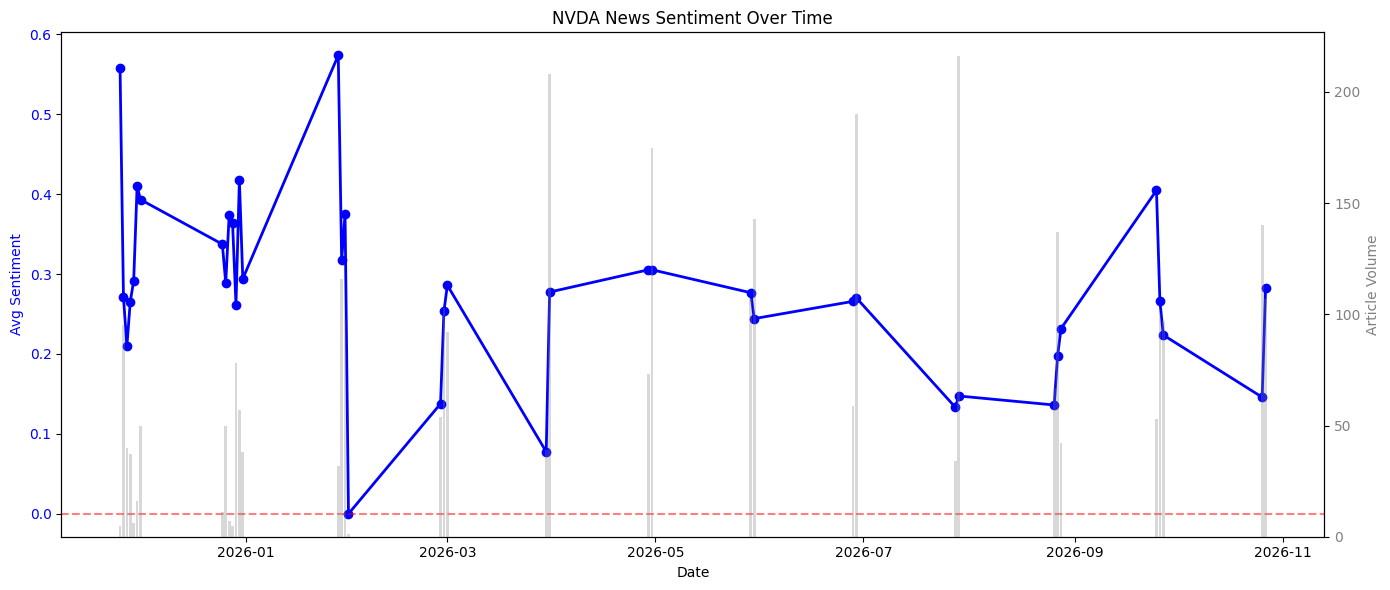

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Done! File downloaded.


In [ ]:
# 1. Install & Import
!pip install vaderSentiment -q
import pandas as pd
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from google.colab import files
import io

# 2. Upload Data
print("Upload your finnhub_news.csv file:")
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

# 3. Process Data & Sentiment
analyzer = SentimentIntensityAnalyzer()
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

# Combine headline and summary for better context
df['text_to_analyze'] = df['headline'].astype(str) + ". " + df['summary'].astype(str)
df['sentiment_score'] = df['text_to_analyze'].apply(lambda x: analyzer.polarity_scores(str(x))['compound'])

def categorize(score):
    if score >= 0.05: return 'Positive'
    elif score <= -0.05: return 'Negative'
    return 'Neutral'

df['sentiment_label'] = df['sentiment_score'].apply(categorize)

# 4. Plot Sentiment vs Time
daily = df.groupby(df['date'].dt.date).agg(
    avg_sentiment=('sentiment_score', 'mean'),
    count=('sentiment_score', 'count')
).reset_index()
daily['date'] = pd.to_datetime(daily['date'])

fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.plot(daily['date'], daily['avg_sentiment'], color='blue', marker='o', linewidth=2, label='Avg Sentiment')
ax1.axhline(0, color='red', linestyle='--', alpha=0.5)
ax1.set_xlabel('Date')
ax1.set_ylabel('Avg Sentiment', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.bar(daily['date'], daily['count'], color='gray', alpha=0.3, label='Article Volume')
ax2.set_ylabel('Article Volume', color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

plt.title('NVDA News Sentiment Over Time')
fig.tight_layout()
plt.show()

# 5. Export
df.to_csv("finnhub_news_with_sentiment.csv", index=False)
files.download("finnhub_news_with_sentiment.csv")
print("Done! File downloaded.")

In [ ]:
!pip install finnhub-python -q
import finnhub
import pandas as pd
import time
from datetime import datetime
from google.colab import files

# 🔑 PUT YOUR FINNHUB API KEY HERE
API_KEY = "dbge0jpr01qiroohh270dbge0jpr01qiroohh27g"
TICKER = "NVDA"

finnhub_client = finnhub.Client(api_key=API_KEY)
all_articles = []

# Finnhub allows querying by date. We will do it month by month to avoid hitting limits.
# 2024-01-01 to 2025-12-31
date_ranges = [
    ("2024-01-01", "2024-06-30"),
    ("2024-07-01", "2024-12-31"),
    ("2025-01-01", "2025-06-30"),
    ("2025-07-01", "2025-12-31")
]

print("Fetching data from Finnhub...")
for start, end in date_ranges:
    try:
        print(f"Fetching {start} to {end}...")
        # Finnhub requires the _from and to parameters
        res = finnhub_client.company_news(TICKER, _from=start, to=end)
        all_articles.extend(res)
        time.sleep(1) # Sleep 1 second to respect rate limits
    except Exception as e:
        print(f"Error fetching {start}-{end}: {e}")

# Convert to DataFrame
df_raw = pd.DataFrame(all_articles)

if not df_raw.empty:
    # Format the unix timestamp to a readable date
    df_raw['date'] = pd.to_datetime(df_raw['datetime'], unit='s')
    # Drop duplicates just in case
    df_raw = df_raw.drop_duplicates(subset=['id'])

    # Save and download
    csv_filename = "finnhub_news_2024_2025.csv"
    df_raw.to_csv(csv_filename, index=False)
    print(f"Success! Saved {len(df_raw)} articles to {csv_filename}")
    files.download(csv_filename)
else:
    print("No articles found. Please check your API key or wait if you hit a rate limit.")

Fetching data from Finnhub...
Fetching 2024-01-01 to 2024-06-30...
Fetching 2024-07-01 to 2024-12-31...
Fetching 2025-01-01 to 2025-06-30...
Fetching 2025-07-01 to 2025-12-31...
Success! Saved 246 articles to finnhub_news_2024_2025.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Please upload your finnhub_news_2024_2025.csv file:


Saving finnhub_news_2024_2025.csv to finnhub_news_2024_2025 (1).csv


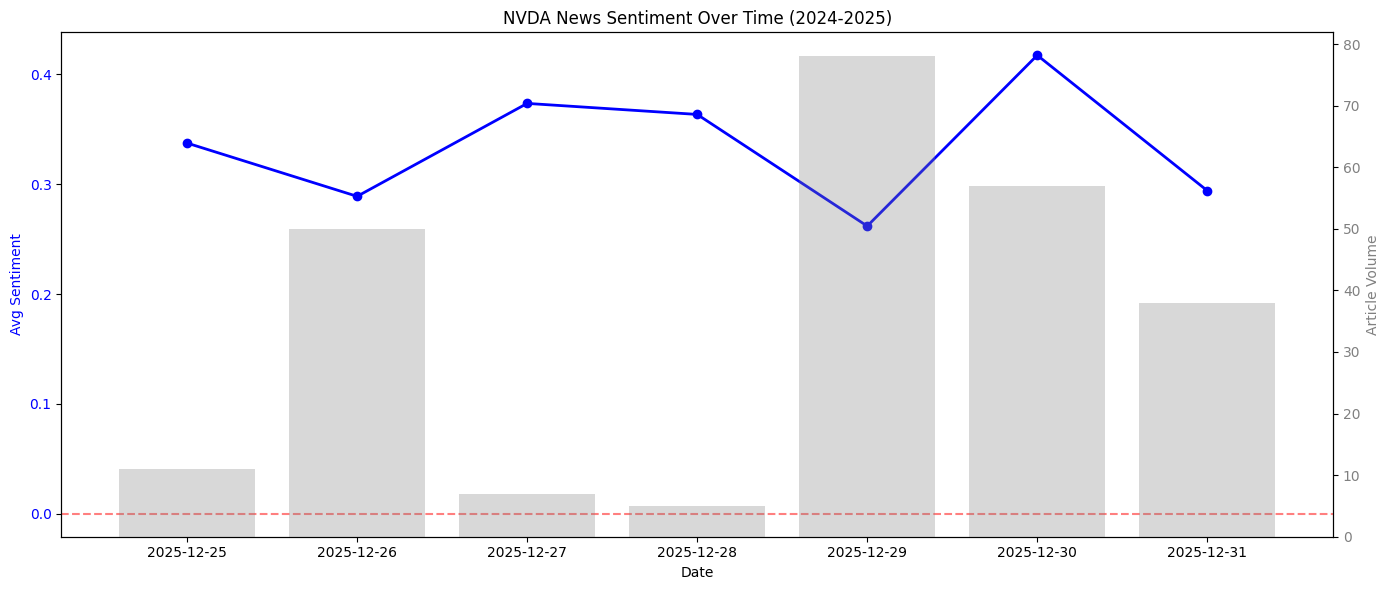

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Done! Sentiment analysis complete and file downloaded.


In [ ]:
!pip install vaderSentiment -q
import pandas as pd
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from google.colab import files
import io

# 1. Upload the CSV you just saved
print("Please upload your finnhub_news_2024_2025.csv file:")
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

# 2. Process Sentiment
analyzer = SentimentIntensityAnalyzer()
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

# Combine headline and summary
df['text_to_analyze'] = df['headline'].astype(str) + ". " + df['summary'].astype(str)
df['sentiment_score'] = df['text_to_analyze'].apply(lambda x: analyzer.polarity_scores(str(x))['compound'])

def categorize(score):
    if score >= 0.05: return 'Positive'
    elif score <= -0.05: return 'Negative'
    return 'Neutral'

df['sentiment_label'] = df['sentiment_score'].apply(categorize)

# 3. Plot Sentiment vs Time
daily = df.groupby(df['date'].dt.date).agg(
    avg_sentiment=('sentiment_score', 'mean'),
    count=('sentiment_score', 'count')
).reset_index()
daily['date'] = pd.to_datetime(daily['date'])

fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.plot(daily['date'], daily['avg_sentiment'], color='blue', marker='o', linewidth=2, label='Avg Sentiment')
ax1.axhline(0, color='red', linestyle='--', alpha=0.5)
ax1.set_xlabel('Date')
ax1.set_ylabel('Avg Sentiment', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.bar(daily['date'], daily['count'], color='gray', alpha=0.3, label='Article Volume')
ax2.set_ylabel('Article Volume', color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

plt.title('NVDA News Sentiment Over Time (2024-2025)')
fig.tight_layout()
plt.show()

# 4. Export final sentiment data for ML
output_file = "finnhub_sentiment_2024_2025.csv"
df.to_csv(output_file, index=False)
files.download(output_file)
print("Done! Sentiment analysis complete and file downloaded.")

Please upload your CSV file:


Saving finnhub_news.csv to finnhub_news (6).csv
Loading FinBERT model...
⚠️ No GPU detected. Going to be a bit slow. (Runtime > Change runtime type > T4 GPU)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Running sentiment analysis...


Processing Batches:   0%|          | 0/94 [00:00<?, ?it/s]

FinBERT Analysis Complete!


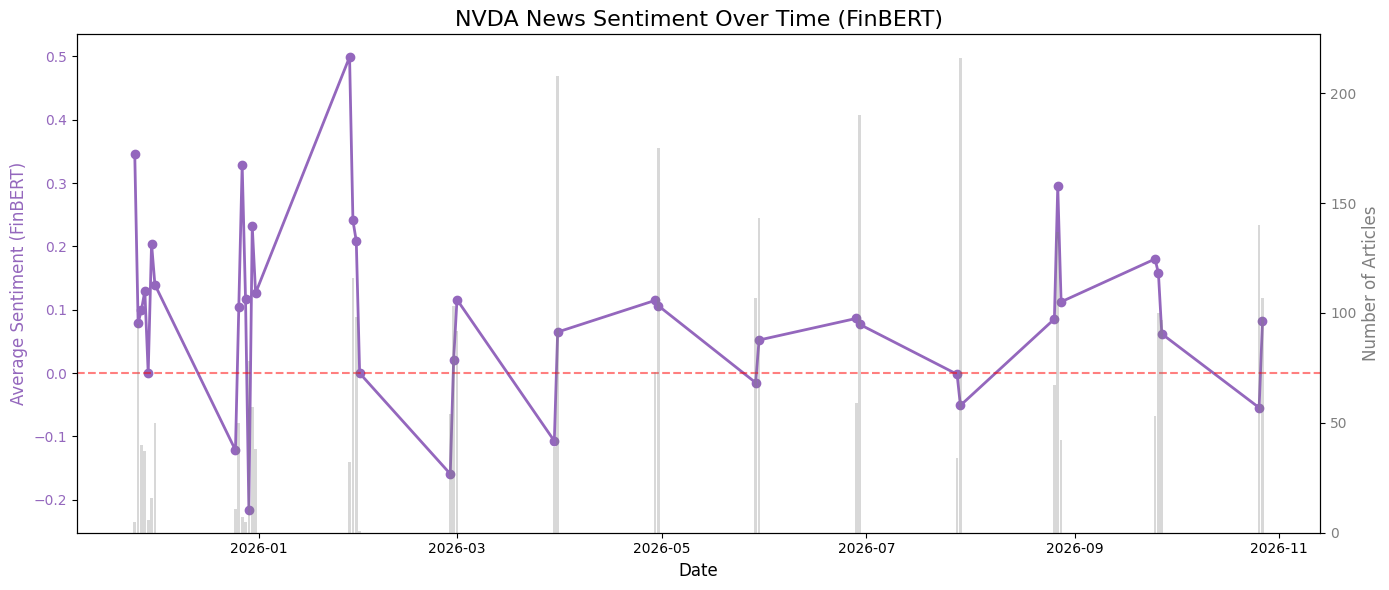

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved and downloaded finbert_sentiment_results.csv


In [ ]:
# 1. Install required libraries
!pip install transformers torch tqdm -q

import pandas as pd
import matplotlib.pyplot as plt
from transformers import pipeline
from google.colab import files
import io
import torch
from tqdm.auto import tqdm  # This gives us the progress bar

# 2. Upload your CSV
print("Please upload your CSV file:")
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

# 3. Process Data
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

# Combine headline and summary (Truncate to 512 characters to prevent errors and speed it up)
df['text_to_analyze'] = (df['headline'].astype(str) + ". " + df['summary'].astype(str)).str[:512]

# 4. Load FinBERT Model
print("Loading FinBERT model...")
device = 0 if torch.cuda.is_available() else -1
if device == 0:
    print("✅ GPU detected! Running fast.")
else:
    print("⚠️ No GPU detected. Going to be a bit slow. (Runtime > Change runtime type > T4 GPU)")

finbert = pipeline("sentiment-analysis", model="ProsusAI/finbert", device=device, truncation=True, max_length=512)

# 5. Run with Progress Bar (Batch processing)
print("Running sentiment analysis...")
texts = df['text_to_analyze'].tolist()
batch_size = 32  # Process 32 articles at a time for speed

all_results = []
# tqdm wraps the loop to show a progress bar
for i in tqdm(range(0, len(texts), batch_size), desc="Processing Batches"):
    batch = texts[i:i + batch_size]
    results = finbert(batch)
    all_results.extend(results)

# 6. Extract results
df['finbert_label'] = [res['label'] for res in all_results]
df['finbert_score'] = [res['score'] for res in all_results]

def calculate_numeric_score(label, score):
    if label == 'positive': return score
    elif label == 'negative': return -score
    else: return 0

df['polarity'] = df.apply(lambda row: calculate_numeric_score(row['finbert_label'], row['finbert_score']), axis=1)

print("FinBERT Analysis Complete!")

# 7. Plot Sentiment vs Time
daily = df.groupby(df['date'].dt.date).agg(
    avg_polarity=('polarity', 'mean'),
    count=('polarity', 'count')
).reset_index()
daily['date'] = pd.to_datetime(daily['date'])

fig, ax1 = plt.subplots(figsize=(14, 6))

color = 'tab:purple'
ax1.set_xlabel('Date', fontsize=12)
ax1.set_ylabel('Average Sentiment (FinBERT)', color=color, fontsize=12)
ax1.plot(daily['date'], daily['avg_polarity'], marker='o', color=color, linewidth=2, label='Avg Sentiment')
ax1.axhline(0, color='red', linestyle='--', alpha=0.5)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color2 = 'tab:gray'
ax2.set_ylabel('Number of Articles', color=color2, fontsize=12)
ax2.bar(daily['date'], daily['count'], color=color2, alpha=0.3, label='Article Volume')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('NVDA News Sentiment Over Time (FinBERT)', fontsize=16)
fig.tight_layout()
plt.grid(axis='x', alpha=0.3)
plt.show()

# 8. Export
output_file = "finbert_sentiment_results.csv"
df.to_csv(output_file, index=False)
files.download(output_file)
print(f"Saved and downloaded {output_file}")

Please upload your CSV file:


Saving finnhub_sentiment_2024_2025.csv to finnhub_sentiment_2024_2025 (1).csv
Loading FinBERT model...
⚠️ No GPU detected. Going to be a bit slow. (Runtime > Change runtime type > T4 GPU)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Running sentiment analysis...


Processing Batches:   0%|          | 0/8 [00:00<?, ?it/s]

FinBERT Analysis Complete!


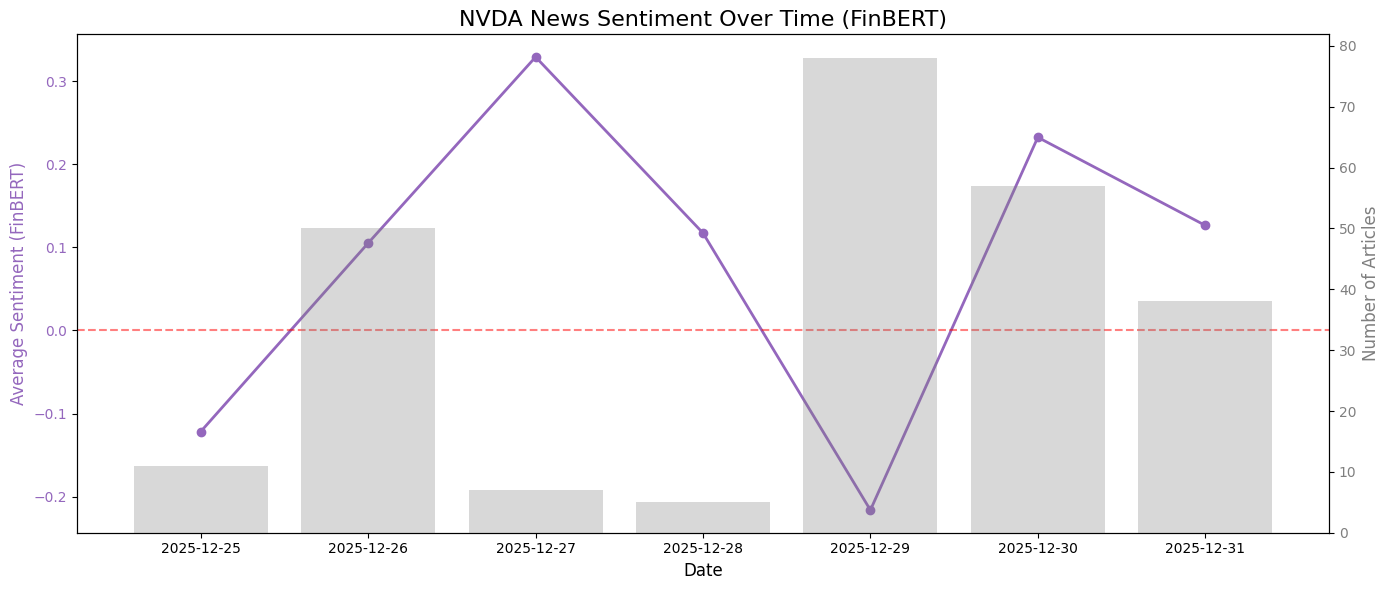

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved and downloaded finbert_sentiment_results.csv


In [4]:
# 1. Install required libraries
!pip install transformers torch tqdm -q

import pandas as pd
import matplotlib.pyplot as plt
from transformers import pipeline
from google.colab import files
import io
import torch
from tqdm.auto import tqdm  # This gives us the progress bar

# 2. Upload your CSV
print("Please upload your CSV file:")
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

# 3. Process Data
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

# Combine headline and summary (Truncate to 512 characters to prevent errors and speed it up)
df['text_to_analyze'] = (df['headline'].astype(str) + ". " + df['summary'].astype(str)).str[:512]

# 4. Load FinBERT Model
print("Loading FinBERT model...")
device = 0 if torch.cuda.is_available() else -1
if device == 0:
    print("✅ GPU detected! Running fast.")
else:
    print("⚠️ No GPU detected. Going to be a bit slow. (Runtime > Change runtime type > T4 GPU)")

finbert = pipeline("sentiment-analysis", model="ProsusAI/finbert", device=device, truncation=True, max_length=512)

# 5. Run with Progress Bar (Batch processing)
print("Running sentiment analysis...")
texts = df['text_to_analyze'].tolist()
batch_size = 32  # Process 32 articles at a time for speed

all_results = []
# tqdm wraps the loop to show a progress bar
for i in tqdm(range(0, len(texts), batch_size), desc="Processing Batches"):
    batch = texts[i:i + batch_size]
    results = finbert(batch)
    all_results.extend(results)

# 6. Extract results
df['finbert_label'] = [res['label'] for res in all_results]
df['finbert_score'] = [res['score'] for res in all_results]

def calculate_numeric_score(label, score):
    if label == 'positive': return score
    elif label == 'negative': return -score
    else: return 0

df['polarity'] = df.apply(lambda row: calculate_numeric_score(row['finbert_label'], row['finbert_score']), axis=1)

print("FinBERT Analysis Complete!")

# 7. Plot Sentiment vs Time
daily = df.groupby(df['date'].dt.date).agg(
    avg_polarity=('polarity', 'mean'),
    count=('polarity', 'count')
).reset_index()
daily['date'] = pd.to_datetime(daily['date'])

fig, ax1 = plt.subplots(figsize=(14, 6))

color = 'tab:purple'
ax1.set_xlabel('Date', fontsize=12)
ax1.set_ylabel('Average Sentiment (FinBERT)', color=color, fontsize=12)
ax1.plot(daily['date'], daily['avg_polarity'], marker='o', color=color, linewidth=2, label='Avg Sentiment')
ax1.axhline(0, color='red', linestyle='--', alpha=0.5)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color2 = 'tab:gray'
ax2.set_ylabel('Number of Articles', color=color2, fontsize=12)
ax2.bar(daily['date'], daily['count'], color=color2, alpha=0.3, label='Article Volume')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('NVDA News Sentiment Over Time (FinBERT)', fontsize=16)
fig.tight_layout()
plt.grid(axis='x', alpha=0.3)
plt.show()

# 8. Export
output_file = "finbert_sentiment_results.csv"
df.to_csv(output_file, index=False)
files.download(output_file)
print(f"Saved and downloaded {output_file}")